# Phase Unwrapping with COOGAR

In this tutorial, we will walk through a 3-dimensional unwrapping example with our COOGAR method, a continuous optimization approach to graph cuts-based phase unwrapping. You will have the option to modify the input image or algorithm parameters at any point. For your convenience, an example phantom has been created. Let's get started.

We recommend using a GPU if available to speed up the computations. The GPU device ID can be set manually as one of the input parameters to COOGAR.

## I. Wrapped Phase Image

We begin by creating a wrapped phase image. You have the option to load your own image; however, it is important to understand your data before applying our algorithm. Questions to consider:
1. Does my data contain any **synthetic** wraps? By **synthetic** wraps, we mean wraps that do not reflect the underlying data and are instead due to an external factor. An example is sharp boundaries that are created when a portion of the image is masked. These discontinuities will change the output unwrapped phase, as they modify the underlying energy function that we wish to minimize. To account for masking or other effects in a medical image, we accept a region of interest mask and only perform unwrapping within that specific region.
2. How many dimensions are the wraps occuring? The underlying algorithm is built to unwrap images in 3-dimensions. If wrapping occurs in only 1-2 dimensions, modification of how you use our method is necessary.

We create a phantom signal (ground truth, unwrapped image) and wrap it to the range (-$\pi$, $\pi$] to simulate an acquired phase image. The ground truth image is saved to validate the accuracy of the unwrapping method.

Please create a temporary folder within this directory to store and retireve the intermediate results. The file path should be specified with the variable `tmp_path` in the code below.

[]

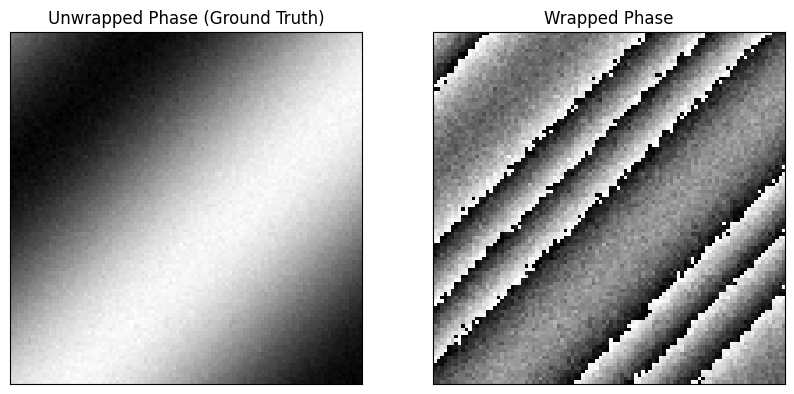

In [1]:
# import necessary packages
import math
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import subprocess

tmp_path = 'tmp'

# create noisy phantom array
def func3D(x, y, z):
    return 10 * math.sin(x + y + z)

image_size = (100, 50, 100)

wrpd = np.zeros(image_size, dtype = np.float32)
unwrpd = np.zeros(image_size, dtype = np.float32)

for i in range(image_size[0]):
    for j in range(image_size[1]):
        for k in range(image_size[2]):
            m = i * 0.04 - image_size[0] / 25
            n = j * 0.04 - image_size[1] / 25
            o = k * 0.04 - image_size[2] / 25
            
            cln = func3D(m, n, o)
            noise = np.random.normal(loc=0.0, scale=0.3)
            
            unw = cln + noise
            wrp = unw % (2 * np.pi) - np.pi
            
            unwrpd[i, j, k] = unw
            wrpd[i, j, k] = wrp
            
# save images to tmp folder (as nibabel dtype)
affine = np.eye(4)
nii_img = nib.Nifti1Image(wrpd, affine)
nib.save(nii_img, f"{tmp_path}/wrpd.nii.gz")

nii_img = nib.Nifti1Image(unwrpd, affine)
nib.save(nii_img, f"{tmp_path}/unwrpd.nii.gz")
            
# display 2D slice of wrapped and unwrapped images
slice_num = image_size[1] // 3
slice_unwrp = unwrpd[:, slice_num, :]
slice_wrp = wrpd[:, slice_num, :]

fig, axes = plt.subplots(1, 2, figsize=(10, 20), squeeze=False)  

axes[0, 0].imshow(slice_unwrp, cmap='gray')
axes[0, 0].set_title('Unwrapped Phase (Ground Truth)')
axes[0, 0].set_yticks([])
axes[0, 0].set_xticks([])

axes[0, 1].imshow(slice_wrp, cmap='gray')
axes[0, 1].set_title('Wrapped Phase')
axes[0, 1].set_yticks([])
axes[0, 1].set_xticks([])

## II. Unwrap with COOGAR

Next, we will unwrap the image using COOGAR. Since we used simulated images, we can compare the unwrapped prediction to the ground truth in order to compute quantitative metrics.

Recall that COOGAR is an iterative method. We must compute and apply multiple graph cuts if the image contains double/triple/quadruple wraps. We can track the progress of the algorithm in this notebook using the tdqm package. 

You can change the input parameters for COOGAR below. See the ReadME in the github page for a complete list of optional input parameters.

In [2]:
# parameters for COOGAR
input_img = f"{tmp_path}/wrpd.nii.gz"
out_dir = f"{tmp_path}"
out_it = 6

cmd = f'coogar --input {input_img} --out-dir {out_dir} --tmp-dir {tmp_path} --outerIter {out_it}'

subprocess.run(cmd, 
               shell=True
               )

Determining cut 1


 16%|█▌        | 810/5000 [00:02<00:13, 300.33it/s, Jg=0.000999]


Energy: 7540535.676102687
Determining cut 2


 41%|████      | 2034/5000 [00:06<00:09, 305.51it/s, Jg=0.001]  


Energy: 6496884.228313895
Determining cut 3


...

 68%|██████▊   | 3411/5000 [00:11<00:05, 304.74it/s, Jg=0.001]  


Energy: 6903354.015968358
Determining cut 5


 69%|██████▊   | 3431/5000 [00:11<00:05, 305.53it/s, Jg=0.001]  


Energy: 5803564.258346166
Phase unwrapping converged.
Unwrapped result saved in tmp/wrpd_coogar-unw.nii.gz


CompletedProcess(args='coogar --input tmp/wrpd.nii.gz --out-dir tmp --tmp-dir tmp --outerIter 6', returncode=0)

# III. Compute Quantitative Metrics and Display

With the unwrapped prediction from COOGAR, we can compute quantitative metrics to validate the unwrapping approach using the ground truth unwrapped signal from above. Note that some signals are shifted from the ground truth by exactly $k\pi$ at every pixel (for some integer $k$). This is common for graph cuts-based unwrapping methods. We account for this by analyzing the data and shifting appropriately, as a translation does not modify the relative data in the underlying signal.

We also visualize a 2D and 1D example of our 3D images.

Mean squared error: 4.024206950036844e-14
Mean relative absolute error: 1.421825257588461e-07
Structured similarity index measure: 1.0000000002809644
Peak signal-to-noise ratio: 160.98073675764851


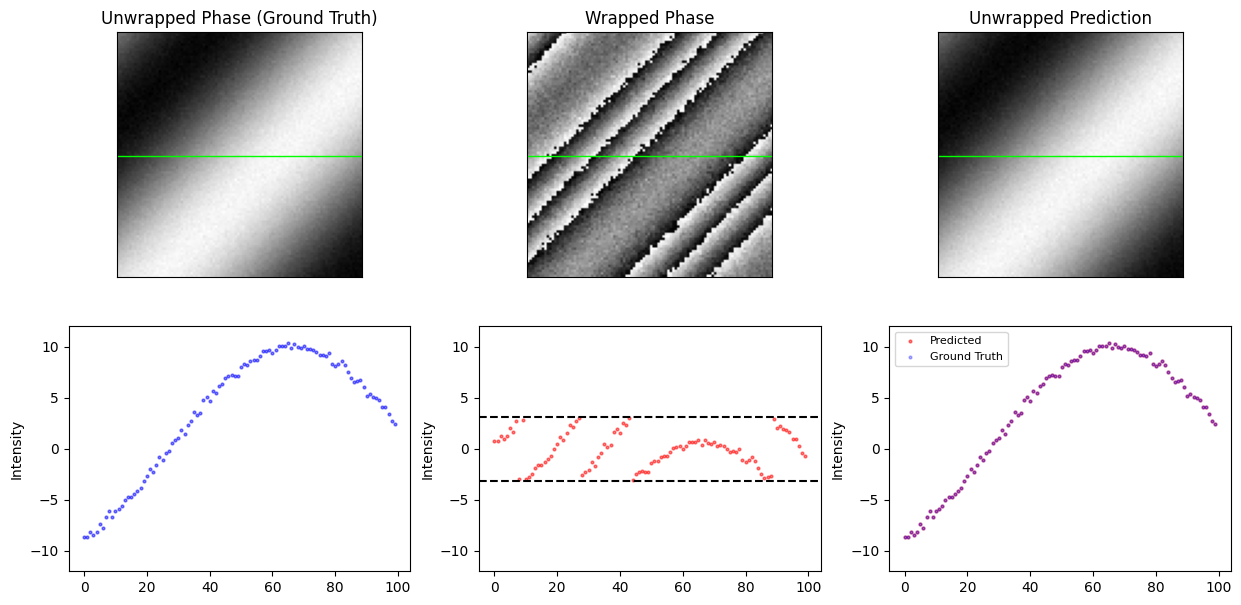

In [3]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

# replace with your unwrapped image if different input was used
unwrp_pred = nib.load(f'{tmp_path}/wrpd_coogar-unw.nii.gz')
unwrp_pred_data = unwrp_pred.get_fdata() - np.pi

# display 2D slices of results
slice_num = image_size[1] // 3
cross_sec = image_size[0] // 2
slice_unwrp = unwrpd[:, slice_num, :]
slice_wrp = wrpd[:, slice_num, :]
slice_pred = unwrp_pred_data[:, slice_num, :]
rnge = image_size[2]

fig, axes = plt.subplots(2, 3, figsize=(15, 7), squeeze=False)  

axes[0, 0].imshow(slice_unwrp, cmap='gray')
axes[0, 0].axhline(y=cross_sec, color='lime', linewidth=1)
axes[0, 0].set_title('Unwrapped Phase (Ground Truth)')
axes[0, 0].set_yticks([])
axes[0, 0].set_xticks([])

axes[1, 0].scatter(range(rnge), slice_unwrp[cross_sec, :], color = 'b', s=4, alpha=.5)
axes[1, 0].set_ylabel('Intensity')
axes[1, 0].set_ylim(-12, 12)

axes[0, 1].imshow(slice_wrp, cmap='gray')
axes[0, 1].axhline(y=cross_sec, color='lime', linewidth=1)
axes[0, 1].set_title('Wrapped Phase')
axes[0, 1].set_yticks([])
axes[0, 1].set_xticks([])

axes[1, 1].scatter(range(rnge), slice_wrp[cross_sec, :], color = 'r', s=4, label='Wrapped', alpha=.5)
axes[1, 1].set_ylabel('Intensity')
axes[1, 1].set_ylim(-12, 12)
axes[1, 1].axhline(y=np.pi, linestyle='--', color='black')
axes[1, 1].axhline(y=-np.pi, linestyle='--', color='black')

axes[0, 2].imshow(slice_pred, cmap='gray')
axes[0, 2].axhline(y=cross_sec, color='lime', linewidth=1)
axes[0, 2].set_title('Unwrapped Prediction')
axes[0, 2].set_yticks([])
axes[0, 2].set_xticks([])

axes[1, 2].scatter(range(rnge), slice_pred[cross_sec, :], color = 'r', s=4, label='Predicted', alpha=.5)
axes[1, 2].scatter(range(rnge), slice_unwrp[cross_sec, :], color = 'b', s=4, label='Ground Truth', alpha=.3)
axes[1, 2].set_ylabel('Intensity')
axes[1, 2].set_ylim(-12, 12)
axes[1, 2].legend(fontsize=8)

# compute quantitative metrics and print
mse = np.mean((unwrpd-unwrp_pred_data)**2)
print(f'Mean squared error: {mse}')

mrae = np.mean(np.divide(
    np.abs(unwrpd - unwrp_pred_data),
    np.abs(unwrpd),
    where=unwrpd != 0
))
print(f'Mean relative absolute error: {mrae}')

ssim = ssim(
    unwrpd,
    unwrp_pred_data,
    data_range=max(unwrpd.max(), unwrp_pred_data.max()) - min(unwrpd.min(), unwrp_pred_data.min())
)
print(f'Structured similarity index measure: {ssim}')

psnr = psnr(
    unwrpd,
    unwrp_pred_data,
    data_range=max(unwrpd.max(), unwrp_pred_data.max()) - min(unwrpd.min(), unwrp_pred_data.min())
)
print(f'Peak signal-to-noise ratio: {psnr}')